# 📊 Feature-by-Feature Visualization Around Thermal Onset ($\tau = 0$)

Using the clean non-redundant dataset (`data/power_grid_simple.csv`), this notebook inspects:
1. The **4-panel verification figure** (same-hour normalized demand surge Train vs Test, raw unnormalized GW load, exogenous thermal discomfort + gas share forcing, and representative heatwave/freeze BAs).
2. **What happens around $\tau = 0$ for every dynamic feature** across all extreme heatwaves and Arctic freezes (`2021–2023` Train vs. `2024` Test).
3. A **single-grid multi-feature walkthrough** (`PJM` June 2024 Heatwave, Test split).
4. A quantitative **before vs. after $\tau = 0$ distribution summary** across all 14 dynamic features.

### 1. Load Libraries and the Simple Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the clean, non-redundant power grid dataset (one row per event per hour)
df = pd.read_csv('data/power_grid_simple.csv')

n_tot = df['sample_id'].nunique()
n_tr = df[df['split'] == 'train']['sample_id'].nunique()
n_te = df[df['split'] == 'test']['sample_id'].nunique()
print(f'Loaded simple dataset: {df.shape[0]:,} rows x {df.shape[1]} columns')
print(f'Unique events: {n_tot} (Train={n_tr}, Test={n_te}), Unique BAs={df["ba"].nunique()}')
df.head(3)

Loaded simple dataset: 82,505 rows x 25 columns
Unique events: 569 (Train=439, Test=130), Unique BAs=49


,sample_id,ba,region,split,event_type,onset_utc,timestamp_utc,tau_hour,latitude,longitude,...,wind_share,import_share,temp_c,humidity_pct,solar_wm2,wind_ms,pressure_hpa,local_hour,day_of_week,thermal_discomfort_c
0,0,CPLE,CAR,train,freeze,2021-01-05 09:00:00,2021-01-02 09:00:00,-72,35.197506,-78.12258,...,0.0,0.025865,17.80,97.31,0.0,5.64,1010.9,4,5,0.200001
1,0,CPLE,CAR,train,freeze,2021-01-05 09:00:00,2021-01-02 10:00:00,-71,35.197506,-78.12258,...,0.0,0.033805,17.42,97.45,0.0,5.68,1011.2,5,5,0.580000
2,0,CPLE,CAR,train,freeze,2021-01-05 09:00:00,2021-01-02 11:00:00,-70,35.197506,-78.12258,...,0.0,0.013338,16.99,97.68,0.0,5.27,1011.4,6,5,1.010000


### 2. 4-Panel Overview Diagram (Reproducible Code for Benchmark Verification Plot)

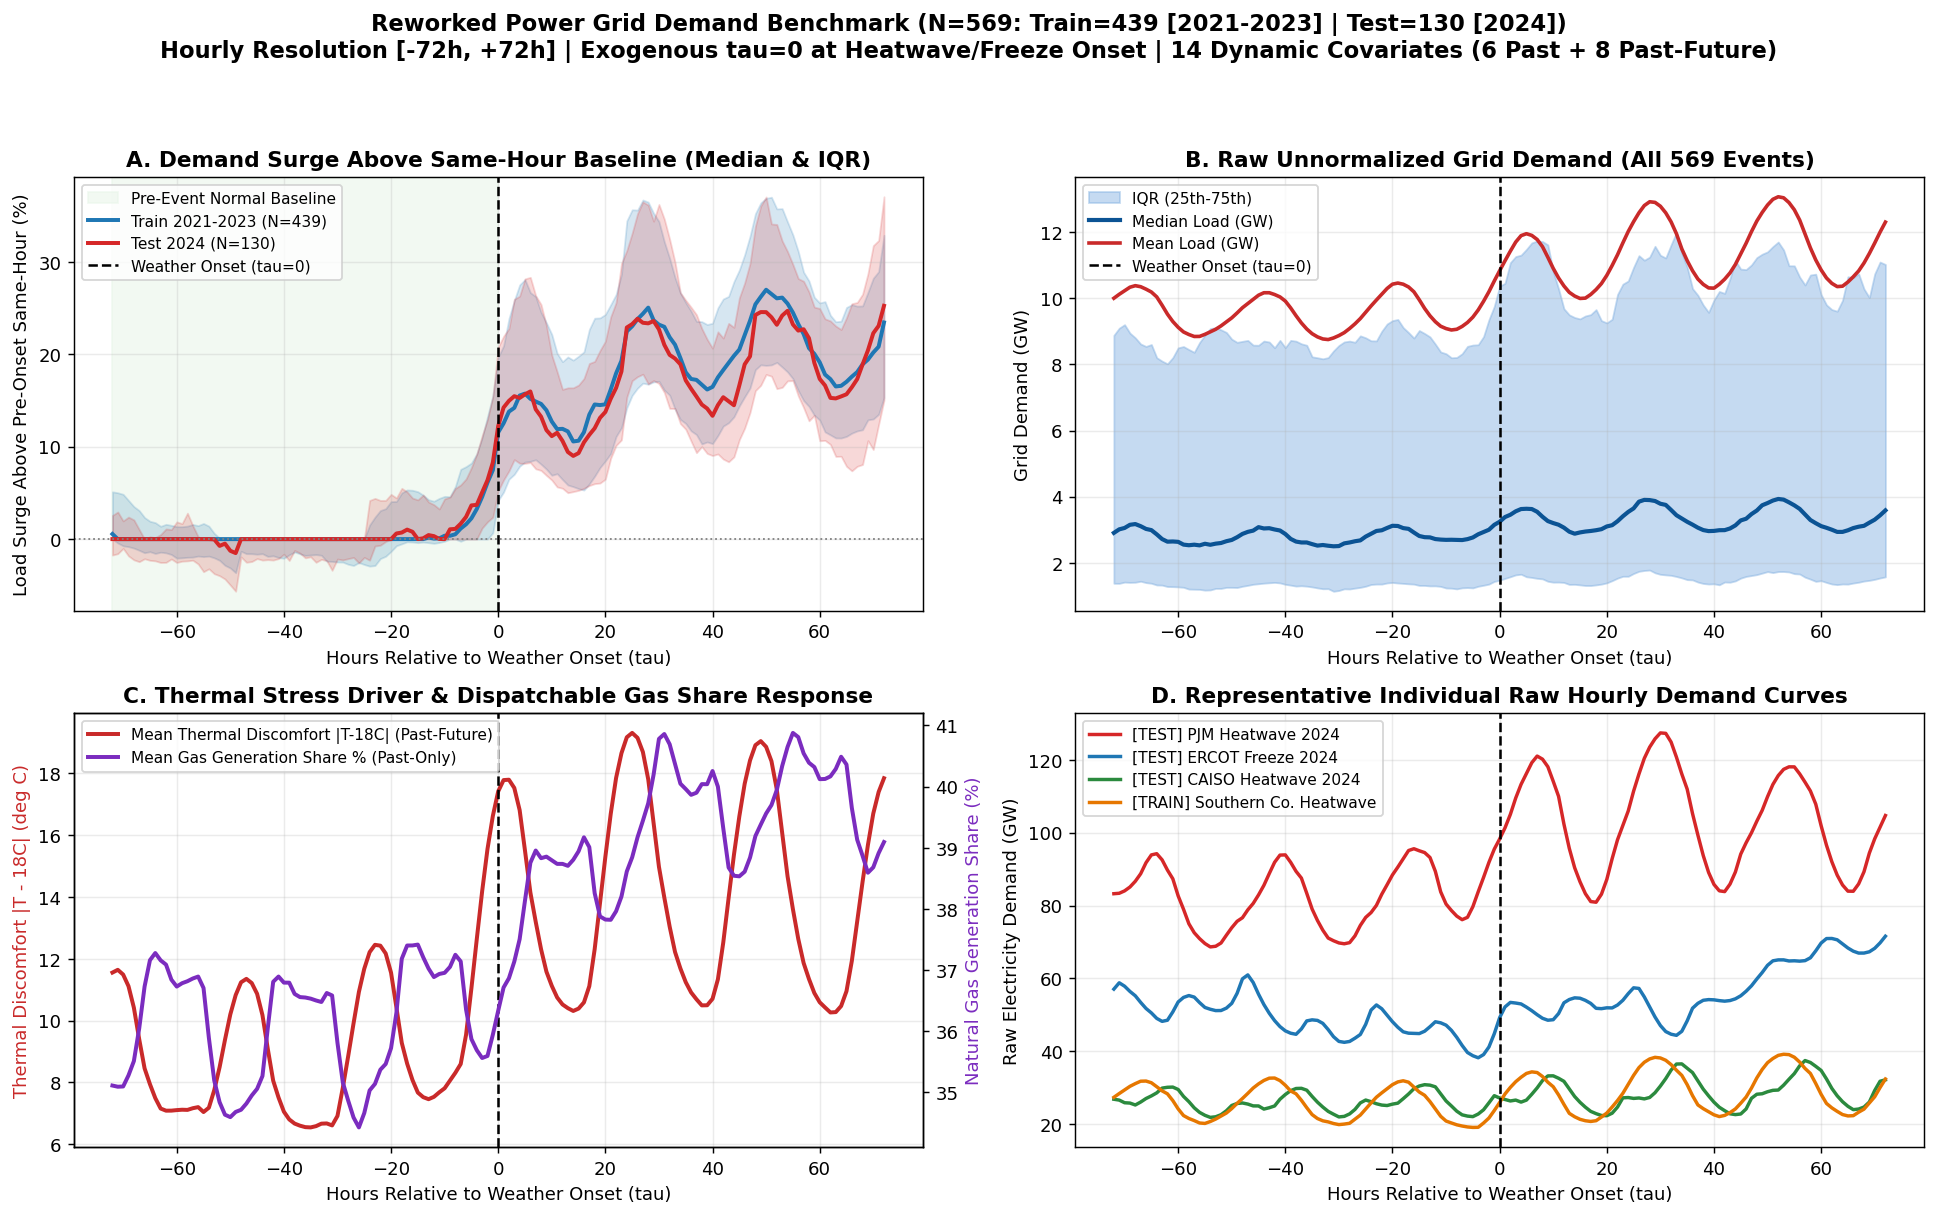

In [2]:
# Compute matching local-hour pre-onset median load per event (cancels 24h diurnal cycle pre-onset)
pre_hr_med = (
    df[df['tau_hour'] < 0]
    .groupby(['sample_id', 'local_hour'])['load_mw']
    .median()
    .rename('pre_same_hr_mw')
    .reset_index()
)
df = df.merge(pre_hr_med, on=['sample_id', 'local_hour'], how='left')
df['excess_load_pct'] = (df['load_mw'] / df['pre_same_hr_mw'] - 1.0) * 100.0

n_tot = df['sample_id'].nunique()
n_tr = df[df['split'] == 'train']['sample_id'].nunique()
n_te = df[df['split'] == 'test']['sample_id'].nunique()

fig, axes = plt.subplots(2, 2, figsize=(15, 9.5), dpi=130)
fig.suptitle(
    f'Reworked Power Grid Demand Benchmark (N={n_tot}: Train={n_tr} [2021-2023] | Test={n_te} [2024])\n'
    'Hourly Resolution [-72h, +72h] | Exogenous tau=0 at Heatwave/Freeze Onset | 14 Dynamic Covariates (6 Past + 8 Past-Future)',
    fontsize=12.5,
    fontweight='bold',
    y=0.98,
)

# --- Panel A: Excess Demand Above Same-Hour Pre-Onset Baseline (Train vs Test) ---
ax = axes[0, 0]
ax.axvspan(-72, 0, color='#e8f5e9', alpha=0.55, label='Pre-Event Normal Baseline')
for split_name, color, label in [('train', '#1f77b4', f'Train 2021-2023 (N={n_tr})'),
                                 ('test', '#d62728', f'Test 2024 (N={n_te})')]:
    sub = df[df['split'] == split_name]
    g = sub.groupby('tau_hour')['excess_load_pct'].agg(
        med='median',
        q25=lambda s: np.percentile(s, 25),
        q75=lambda s: np.percentile(s, 75),
    ).reset_index()
    ax.plot(g['tau_hour'], g['med'], color=color, lw=2.2, label=label)
    ax.fill_between(g['tau_hour'], g['q25'], g['q75'], color=color, alpha=0.18)

ax.axvline(0, color='black', ls='--', lw=1.4, label='Weather Onset (tau=0)')
ax.axhline(0, color='gray', ls=':', lw=1.0)
ax.set_title('A. Demand Surge Above Same-Hour Baseline (Median & IQR)', fontweight='bold')
ax.set_xlabel('Hours Relative to Weather Onset (tau)')
ax.set_ylabel('Load Surge Above Pre-Onset Same-Hour (%)')
ax.grid(True, alpha=0.25)
ax.legend(loc='upper left', fontsize=8.5)

# --- Panel B: Raw Unnormalized Grid Load Across All Events (GW) ---
ax = axes[0, 1]
raw_stats = (df.groupby('tau_hour')['load_mw'].agg(
    med='median',
    mean='mean',
    q25=lambda s: np.percentile(s, 25),
    q75=lambda s: np.percentile(s, 75),
) / 1000.0).reset_index()
ax.fill_between(raw_stats['tau_hour'], raw_stats['q25'], raw_stats['q75'], color='#7faee0', alpha=0.45, label='IQR (25th-75th)')
ax.plot(raw_stats['tau_hour'], raw_stats['med'], color='#0b5394', lw=2.3, label='Median Load (GW)')
ax.plot(raw_stats['tau_hour'], raw_stats['mean'], color='#c92a2a', lw=2.0, label='Mean Load (GW)')
ax.axvline(0, color='black', ls='--', lw=1.4, label='Weather Onset (tau=0)')
ax.set_title(f'B. Raw Unnormalized Grid Demand (All {n_tot} Events)', fontweight='bold')
ax.set_xlabel('Hours Relative to Weather Onset (tau)')
ax.set_ylabel('Grid Demand (GW)')
ax.grid(True, alpha=0.25)
ax.legend(loc='upper left', fontsize=8.5)

# --- Panel C: Mean Exogenous Thermal Stress (Past-Future) & Peaking Gas Share (Past-Only) ---
ax = axes[1, 0]
ax_r = ax.twinx()
grp_f = df.groupby('tau_hour')[['thermal_discomfort_c', 'gas_share']].mean().reset_index()
l_td, = ax.plot(grp_f['tau_hour'], grp_f['thermal_discomfort_c'], color='#c92a2a', lw=2.2, label='Mean Thermal Discomfort |T-18C| (Past-Future)')
l_gs, = ax_r.plot(grp_f['tau_hour'], grp_f['gas_share'] * 100.0, color='#7b2cbf', lw=2.2, label='Mean Gas Generation Share % (Past-Only)')
ax.axvline(0, color='black', ls='--', lw=1.4)
ax.set_title('C. Thermal Stress Driver & Dispatchable Gas Share Response', fontweight='bold')
ax.set_xlabel('Hours Relative to Weather Onset (tau)')
ax.set_ylabel('Thermal Discomfort |T - 18C| (deg C)', color='#c92a2a')
ax_r.set_ylabel('Natural Gas Generation Share (%)', color='#7b2cbf')
ax.grid(True, alpha=0.25)
ax.legend([l_td, l_gs], [l_td.get_label(), l_gs.get_label()], loc='upper left', fontsize=8.5)

# --- Panel D: Representative Raw Individual Grid Surges (Heatwaves vs Freezes) ---
ax = axes[1, 1]
picks = []
for ba, sp, et, col, lbl in [
    ('PJM', 'test', 'heatwave', '#d62728', '[TEST] PJM Heatwave 2024'),
    ('ERCO', 'test', 'freeze', '#1f77b4', '[TEST] ERCOT Freeze 2024'),
    ('CISO', 'test', 'heatwave', '#2b8a3e', '[TEST] CAISO Heatwave 2024'),
    ('SOCO', 'train', 'heatwave', '#e67700', '[TRAIN] Southern Co. Heatwave'),
]:
    m = df[(df['ba'] == ba) & (df['split'] == sp) & (df['event_type'] == et)]
    if not m.empty:
        sid = m['sample_id'].iloc[0]
        sub = df[df['sample_id'] == sid].sort_values('tau_hour')
        ax.plot(sub['tau_hour'], sub['load_mw'] / 1000.0, color=col, lw=1.9, label=lbl)

ax.axvline(0, color='black', ls='--', lw=1.4)
ax.set_title('D. Representative Individual Raw Hourly Demand Curves', fontweight='bold')
ax.set_xlabel('Hours Relative to Weather Onset (tau)')
ax.set_ylabel('Raw Electricity Demand (GW)')
ax.grid(True, alpha=0.25)
ax.legend(loc='upper left', fontsize=8.5)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('data/power_grid_verification.png', dpi=150, bbox_inches='tight')
plt.show()

### 3. What Happens Around $\tau = 0$ for Every Single Feature

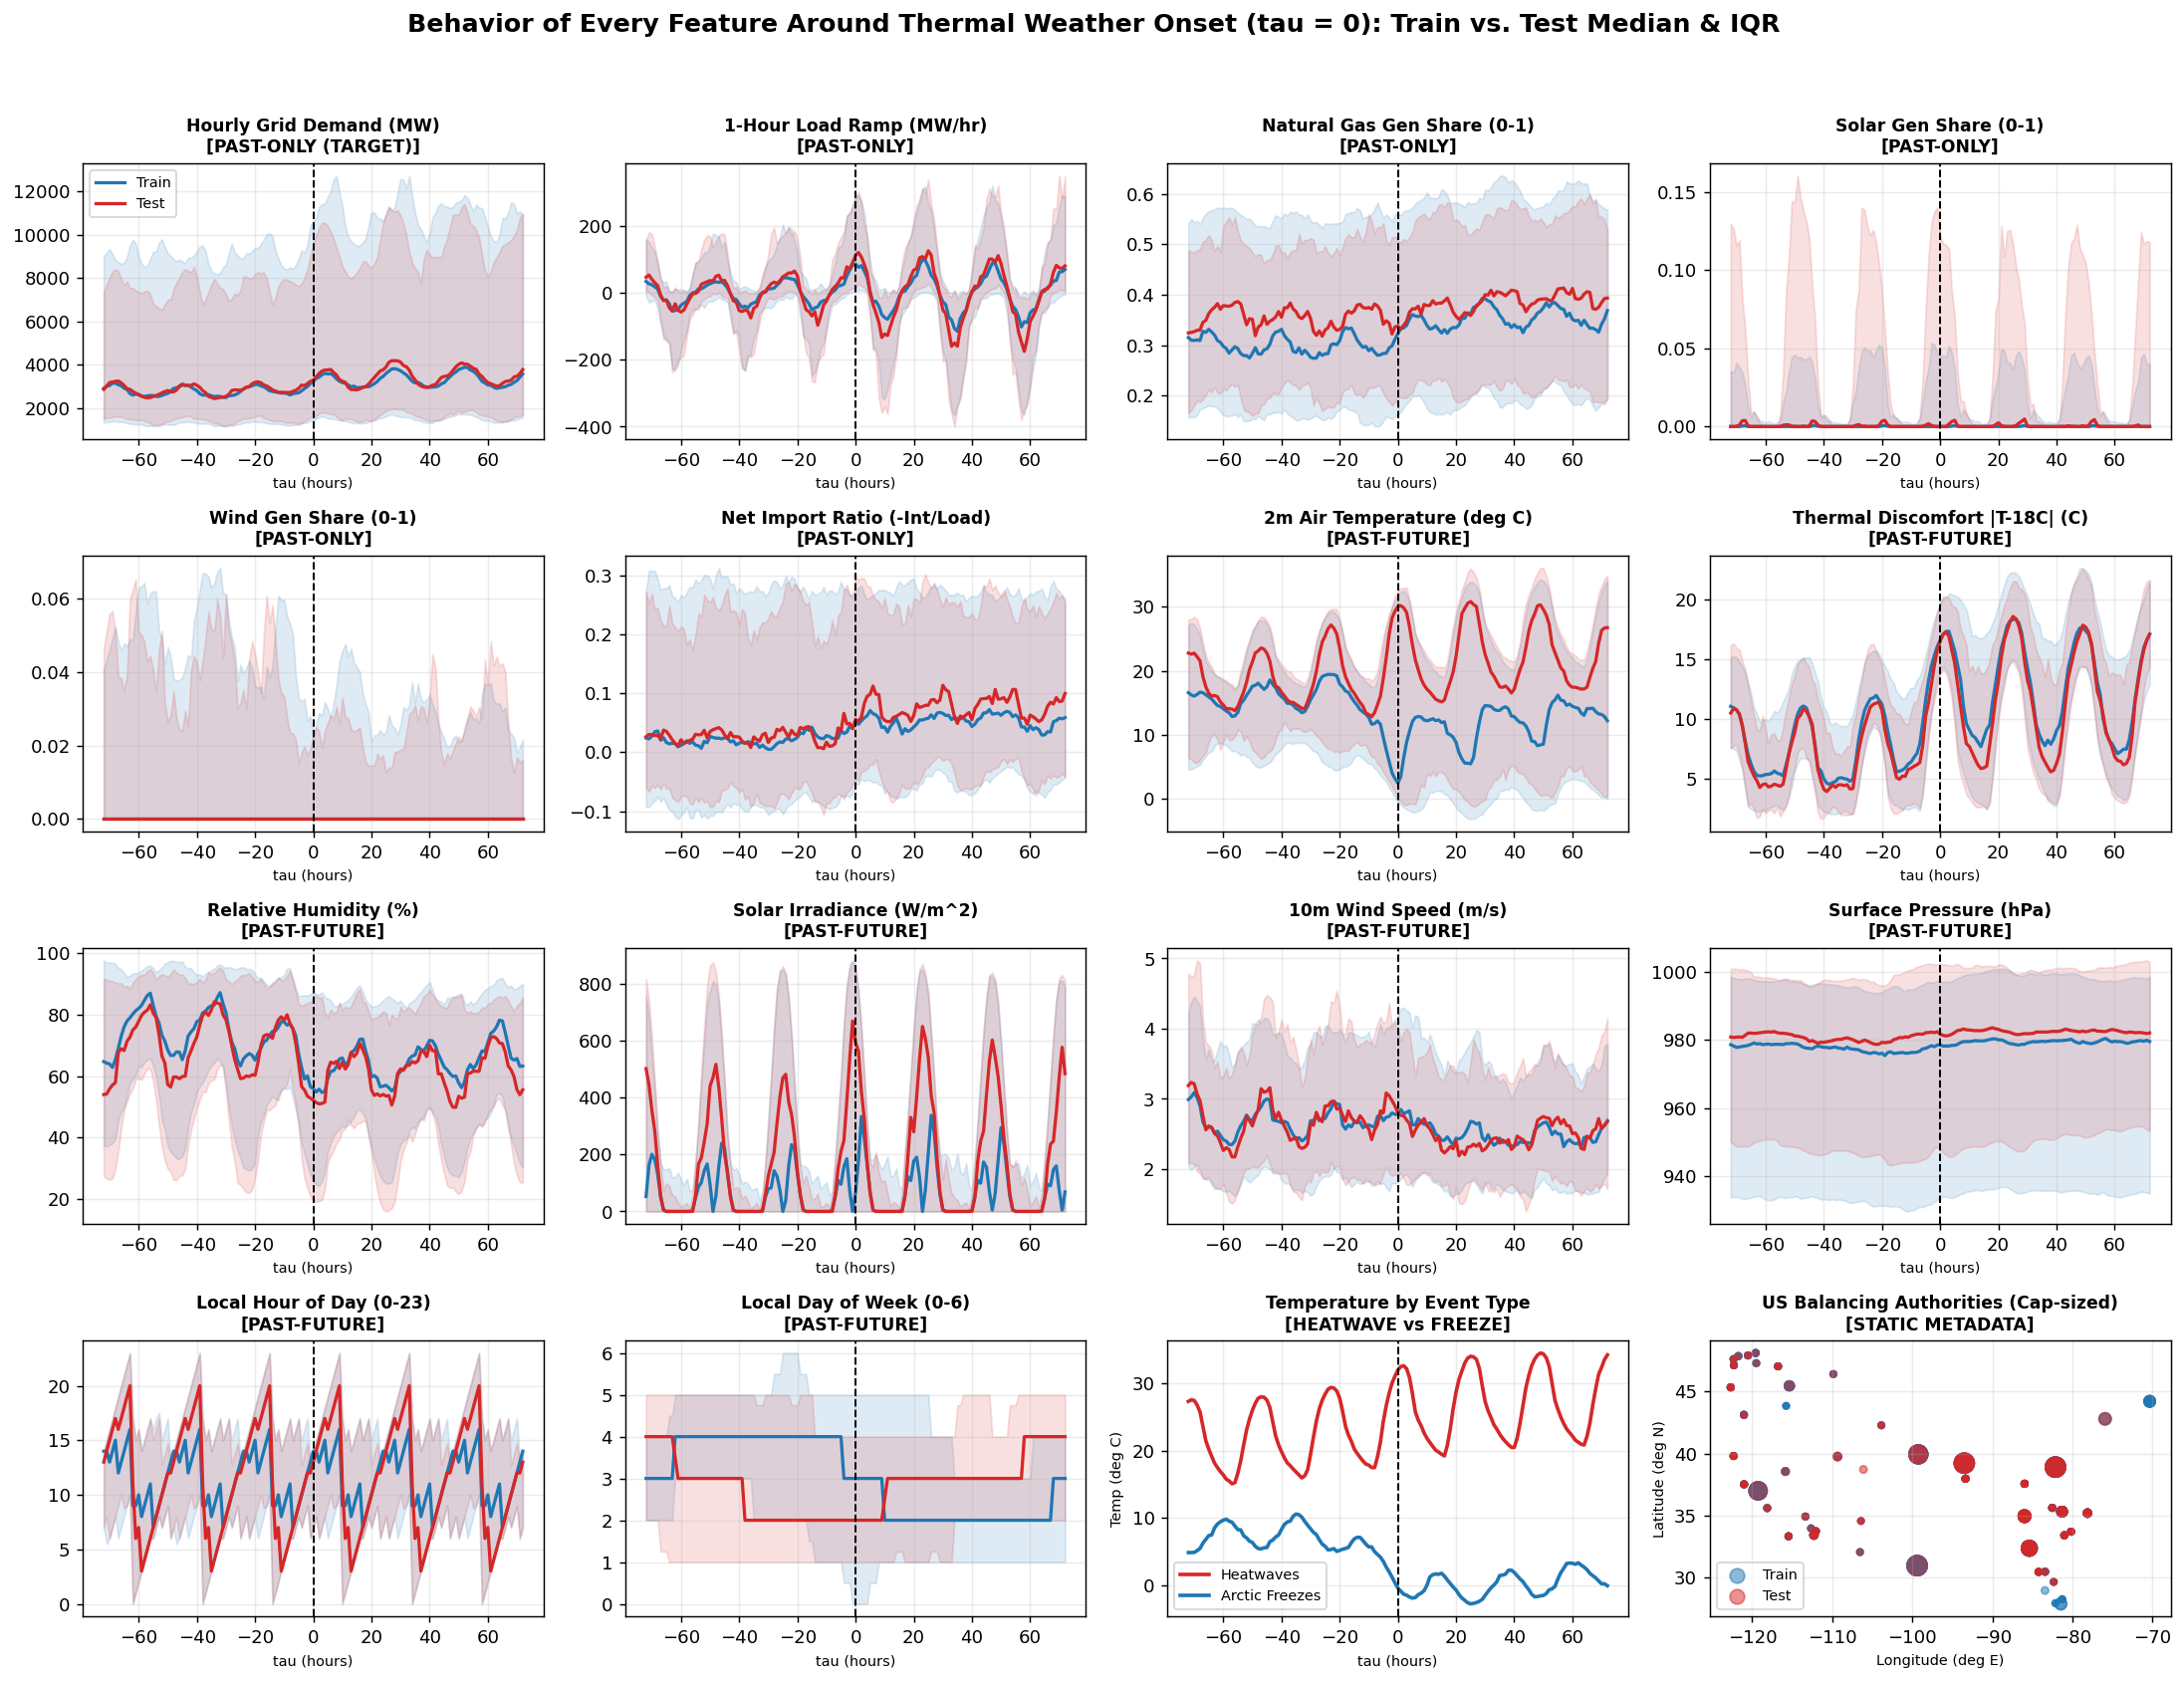

In [3]:
# Human-readable labels & units for all 14 dynamic features (6 past-only + 8 past-future)
FEATURES = [
    ('load_mw', 'Hourly Grid Demand (MW)', 'PAST-ONLY (TARGET)'),
    ('load_change_1h', '1-Hour Load Ramp (MW/hr)', 'PAST-ONLY'),
    ('gas_share', 'Natural Gas Gen Share (0-1)', 'PAST-ONLY'),
    ('solar_share', 'Solar Gen Share (0-1)', 'PAST-ONLY'),
    ('wind_share', 'Wind Gen Share (0-1)', 'PAST-ONLY'),
    ('import_share', 'Net Import Ratio (-Int/Load)', 'PAST-ONLY'),
    ('temp_c', '2m Air Temperature (deg C)', 'PAST-FUTURE'),
    ('thermal_discomfort_c', 'Thermal Discomfort |T-18C| (C)', 'PAST-FUTURE'),
    ('humidity_pct', 'Relative Humidity (%)', 'PAST-FUTURE'),
    ('solar_wm2', 'Solar Irradiance (W/m^2)', 'PAST-FUTURE'),
    ('wind_ms', '10m Wind Speed (m/s)', 'PAST-FUTURE'),
    ('pressure_hpa', 'Surface Pressure (hPa)', 'PAST-FUTURE'),
    ('local_hour', 'Local Hour of Day (0-23)', 'PAST-FUTURE'),
    ('day_of_week', 'Local Day of Week (0-6)', 'PAST-FUTURE'),
]

fig, axes = plt.subplots(4, 4, figsize=(17, 13), dpi=130)
axes = axes.flatten()

# Notice heatwaves & freezes pull temp_c in opposite directions, so Panel thermal_discomfort_c shows unified forcing!
for idx, (col, label, role) in enumerate(FEATURES):
    ax = axes[idx]
    for split_name, color, name in [('train', '#1f77b4', 'Train'), ('test', '#d62728', 'Test')]:
        sub = df[df['split'] == split_name]
        g = sub.groupby('tau_hour')[col].agg(
            med='median',
            q25=lambda s: np.percentile(s, 25),
            q75=lambda s: np.percentile(s, 75),
        ).reset_index()
        ax.plot(g['tau_hour'], g['med'], color=color, lw=1.8, label=name)
        ax.fill_between(g['tau_hour'], g['q25'], g['q75'], color=color, alpha=0.14)

    ax.axvline(0, color='black', ls='--', lw=1.1)
    ax.set_title(f'{label}\n[{role}]', fontsize=9.5, fontweight='bold')
    ax.set_xlabel('tau (hours)', fontsize=8)
    ax.grid(True, alpha=0.25)
    if idx == 0:
        ax.legend(loc='upper left', fontsize=8)

# Remaining 2 grid slots for heatwave/freeze temperature separation + US BA spatial map
ax_s1 = axes[14]
for etype, color, lbl in [('heatwave', '#d62728', 'Heatwaves'), ('freeze', '#1f77b4', 'Arctic Freezes')]:
    sub = df[df['event_type'] == etype]
    g = sub.groupby('tau_hour')['temp_c'].median()
    ax_s1.plot(g.index, g.values, color=color, lw=2.0, label=lbl)
ax_s1.axvline(0, color='black', ls='--', lw=1.1)
ax_s1.set_title('Temperature by Event Type\n[HEATWAVE vs FREEZE]', fontsize=9.5, fontweight='bold')
ax_s1.set_xlabel('tau (hours)', fontsize=8)
ax_s1.set_ylabel('Temp (deg C)', fontsize=8)
ax_s1.grid(True, alpha=0.25)
ax_s1.legend(loc='lower left', fontsize=8)

ax_s2 = axes[15]
meta_u = df.drop_duplicates('sample_id')
for split_name, color, name in [('train', '#1f77b4', 'Train'), ('test', '#d62728', 'Test')]:
    sub = meta_u[meta_u['split'] == split_name]
    ax_s2.scatter(sub['longitude'], sub['latitude'], s=np.clip(sub['installed_cap_mw'] / 1000.0, 12, 120), alpha=0.5, color=color, label=name)
ax_s2.set_title('US Balancing Authorities (Cap-sized)\n[STATIC METADATA]', fontsize=9.5, fontweight='bold')
ax_s2.set_xlabel('Longitude (deg E)', fontsize=8)
ax_s2.set_ylabel('Latitude (deg N)', fontsize=8)
ax_s2.grid(True, alpha=0.25)
ax_s2.legend(loc='lower left', fontsize=8)

plt.suptitle(
    'Behavior of Every Feature Around Thermal Weather Onset (tau = 0): Train vs. Test Median & IQR',
    fontsize=14,
    fontweight='bold',
    y=0.995,
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig('data/power_grid_all_features_around_surge.png', dpi=150, bbox_inches='tight')
plt.show()

### 4. Detailed Single-Grid Walkthrough Across Key Features

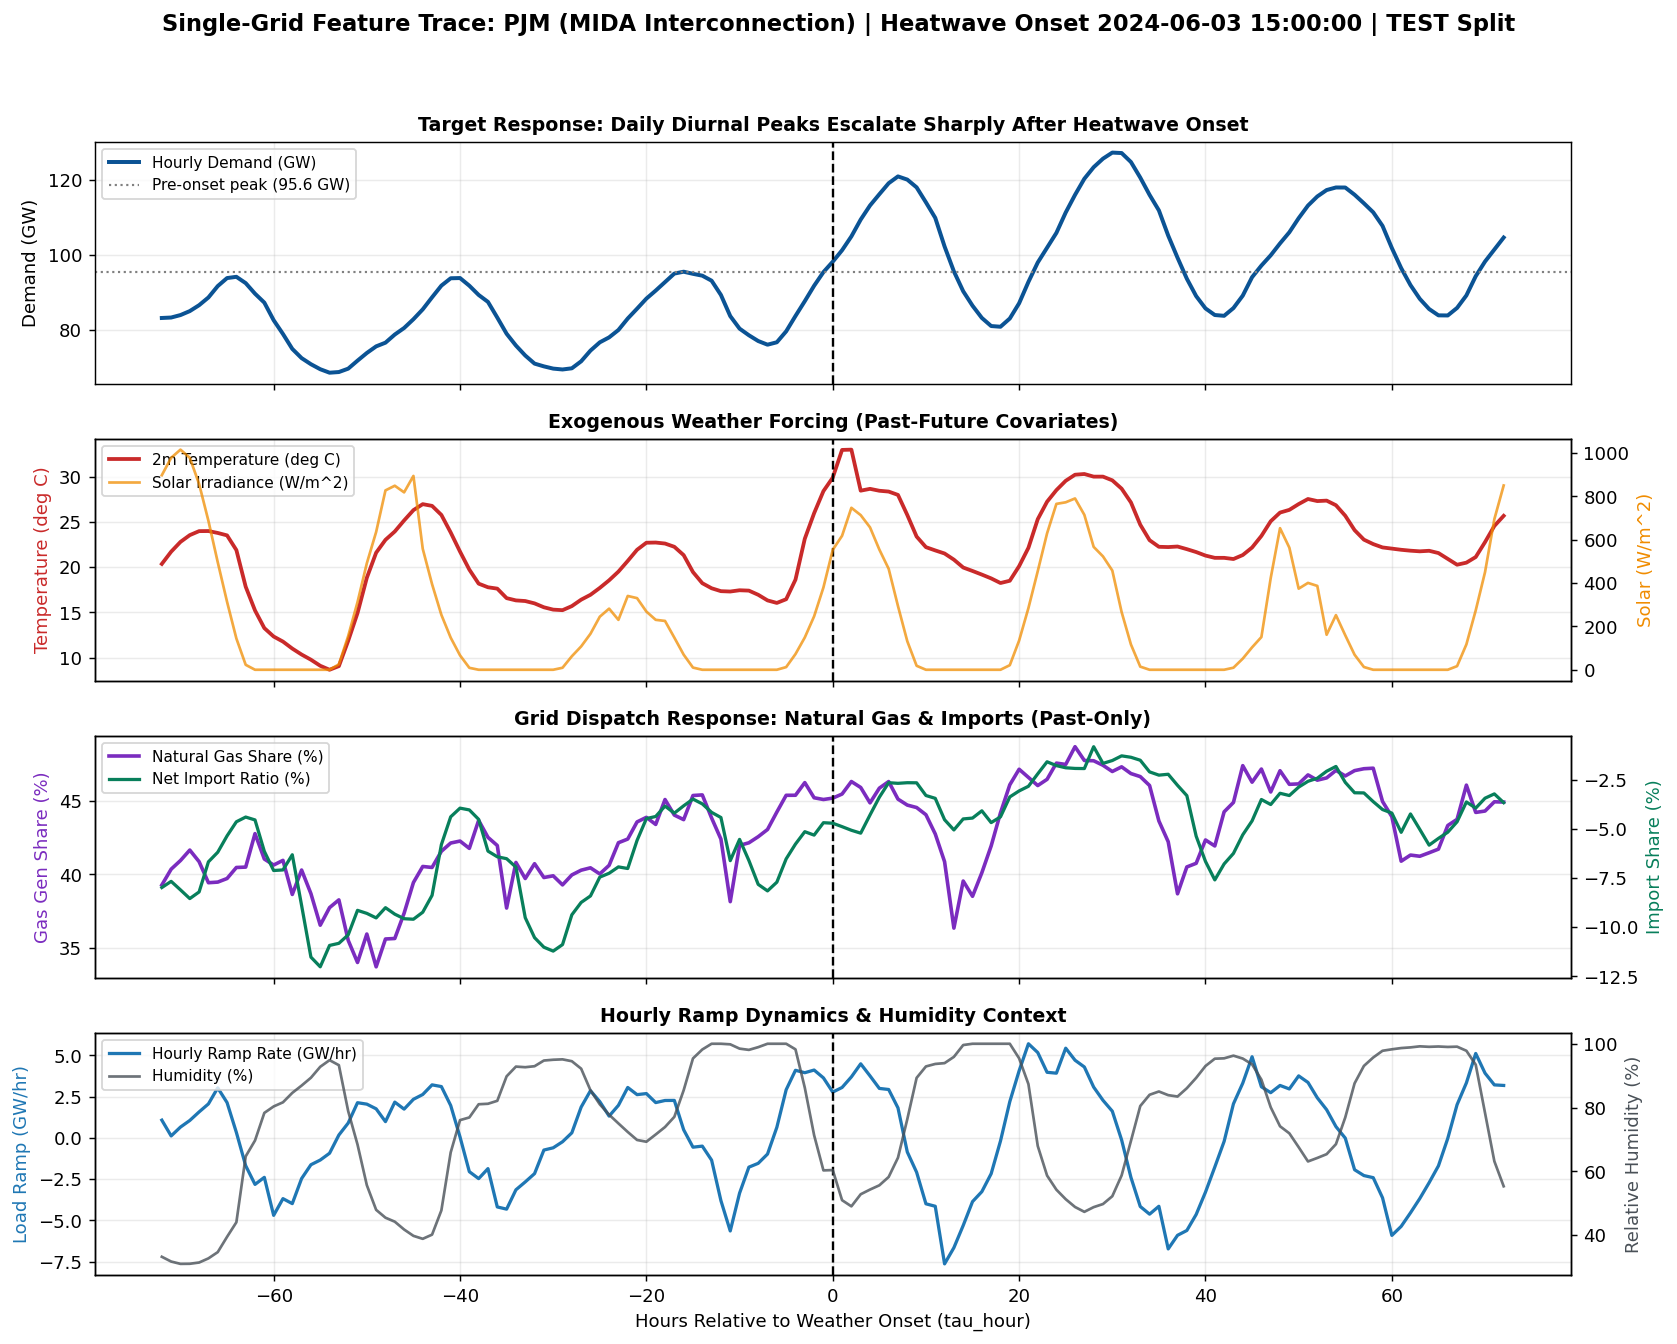

In [4]:
# Pick one dramatic Test-split grid surge: PJM June 2024 Heatwave
pjm_rows = df[(df['ba'] == 'PJM') & (df['split'] == 'test') & (df['event_type'] == 'heatwave')]
sid = pjm_rows['sample_id'].iloc[0]
sample = df[df['sample_id'] == sid].sort_values('tau_hour')
meta_r = sample.iloc[0]

fig, axes = plt.subplots(4, 1, figsize=(13, 10.5), dpi=130, sharex=True)
fig.suptitle(
    f'Single-Grid Feature Trace: {meta_r["ba"]} ({meta_r["region"]} Interconnection) | '
    f'{meta_r["event_type"].title()} Onset {meta_r["onset_utc"]} | {meta_r["split"].upper()} Split',
    fontsize=12.5,
    fontweight='bold',
    y=0.98,
)

# 1. Target electricity load
axes[0].plot(sample['tau_hour'], sample['load_mw'] / 1000.0, color='#0b5394', lw=2.2, label='Hourly Demand (GW)')
pre_max_gw = sample[sample['tau_hour'] < 0]['load_mw'].max() / 1000.0
axes[0].axhline(pre_max_gw, color='gray', ls=':', lw=1.2, label=f'Pre-onset peak ({pre_max_gw:.1f} GW)')
axes[0].set_ylabel('Demand (GW)')
axes[0].set_title('Target Response: Daily Diurnal Peaks Escalate Sharply After Heatwave Onset', fontweight='bold', fontsize=10.5)
axes[0].legend(loc='upper left', fontsize=8.5)

# 2. Forecastable heat & solar drivers (Past-Future)
ax1_r = axes[1].twinx()
l_t, = axes[1].plot(sample['tau_hour'], sample['temp_c'], color='#c92a2a', lw=2.1, label='2m Temperature (deg C)')
l_s, = ax1_r.plot(sample['tau_hour'], sample['solar_wm2'], color='#f08c00', lw=1.5, alpha=0.75, label='Solar Irradiance (W/m^2)')
axes[1].set_ylabel('Temperature (deg C)', color='#c92a2a')
ax1_r.set_ylabel('Solar (W/m^2)', color='#f08c00')
axes[1].set_title('Exogenous Weather Forcing (Past-Future Covariates)', fontweight='bold', fontsize=10.5)
axes[1].legend([l_t, l_s], [l_t.get_label(), l_s.get_label()], loc='upper left', fontsize=8.5)

# 3. Peaking generation & import stress (Past-Only)
ax2_r = axes[2].twinx()
l_g, = axes[2].plot(sample['tau_hour'], sample['gas_share'] * 100.0, color='#7b2cbf', lw=2.0, label='Natural Gas Share (%)')
l_i, = ax2_r.plot(sample['tau_hour'], sample['import_share'] * 100.0, color='#087f5b', lw=1.8, label='Net Import Ratio (%)')
axes[2].set_ylabel('Gas Gen Share (%)', color='#7b2cbf')
ax2_r.set_ylabel('Import Share (%)', color='#087f5b')
axes[2].set_title('Grid Dispatch Response: Natural Gas & Imports (Past-Only)', fontweight='bold', fontsize=10.5)
axes[2].legend([l_g, l_i], [l_g.get_label(), l_i.get_label()], loc='upper left', fontsize=8.5)

# 4. Humidity & ramp rate
ax3_r = axes[3].twinx()
l_r, = axes[3].plot(sample['tau_hour'], sample['load_change_1h'] / 1000.0, color='#1f77b4', lw=1.8, label='Hourly Ramp Rate (GW/hr)')
l_h, = ax3_r.plot(sample['tau_hour'], sample['humidity_pct'], color='#495057', lw=1.5, alpha=0.8, label='Humidity (%)')
axes[3].set_ylabel('Load Ramp (GW/hr)', color='#1f77b4')
ax3_r.set_ylabel('Relative Humidity (%)', color='#495057')
axes[3].set_xlabel('Hours Relative to Weather Onset (tau_hour)')
axes[3].set_title('Hourly Ramp Dynamics & Humidity Context', fontweight='bold', fontsize=10.5)
axes[3].legend([l_r, l_h], [l_r.get_label(), l_h.get_label()], loc='upper left', fontsize=8.5)

for a in axes:
    a.axvline(0, color='black', ls='--', lw=1.3)
    a.grid(True, alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('data/power_grid_single_region_features.png', dpi=150, bbox_inches='tight')
plt.show()

### 5. Before vs. After $\tau = 0$: Numerical Comparison Across All Events

In [5]:
before = df[df['tau_hour'] < 0]
after = df[df['tau_hour'] >= 0]

rows = []
for col, label, role in FEATURES:
    pre_med = before[col].median()
    post_med = after[col].median()
    pre_peak = before.groupby('sample_id')[col].max().median()
    post_peak = after.groupby('sample_id')[col].max().median()
    rows.append({
        'Feature': col,
        'Role': role,
        'Pre-Onset Median': round(pre_med, 2),
        'Post-Onset Median': round(post_med, 2),
        'Pre-Onset Peak Median': round(pre_peak, 2),
        'Post-Onset Peak Median': round(post_peak, 2),
        'Median Shift': round(post_med - pre_med, 2),
    })

summary_tbl = pd.DataFrame(rows)
display(summary_tbl)

,Feature,Role,Pre-Onset Median,Post-Onset Median,Pre-Onset Peak Median,Post-Onset Peak Median,Median Shift
0,load_mw,PAST-ONLY (TARGET),2811.00,3388.00,3502.00,4313.00,577.00
1,load_change_1h,PAST-ONLY,0.00,2.00,289.00,350.00,2.00
2,gas_share,PAST-ONLY,0.32,0.36,0.45,0.47,0.05
3,solar_share,PAST-ONLY,0.00,0.00,0.04,0.04,0.00
4,wind_share,PAST-ONLY,0.00,0.00,0.00,0.00,0.00
5,import_share,PAST-ONLY,0.02,0.06,0.17,0.18,0.04
6,temp_c,PAST-FUTURE,15.36,15.34,28.39,30.62,-0.02
7,thermal_discomfort_c,PAST-FUTURE,8.08,13.62,16.14,20.77,5.54
8,humidity_pct,PAST-FUTURE,74.88,64.42,99.88,97.37,-10.46
9,solar_wm2,PAST-FUTURE,5.55,6.35,749.03,770.60,0.80
